This notebook performs standard data preprocessing and exploratory data analysis on the campus Lost & Found dataset (120,000 records):
1. **Data Ingestion:** Load and inspect raw tabular data.
2. **Data Quality & Integrity:** Check for missing values, duplicates, and data types.
3. **Data Cleaning:** Handle missing values, strip whitespace, and normalize string fields.
4. **Date Processing:** Parse timestamps and extract calendar features (month, day of week, weekend flag).
5. **Target Realignment:** Standardize target recovery status into the 3 defined classes (`Pending`, `Recovered`, `Closed`).
6. **Exploratory Visualizations:** Analyze distributions of categories, campus locations, and status outcomes.
7. **Dataset Export:** Export the clean processed dataset ready for model training.


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['figure.dpi'] = 100

print('[OK] Libraries imported successfully.')


[OK] Libraries imported successfully.


## 1. Data Ingestion
We load the campus Lost & Found dataset containing 120,000 records.


In [ ]:
DATA_PATH = os.path.join('..', 'data', 'smart_campus_dataset_120k.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = r'C:\Users\GOPI CHAND\OneDrive\Documents\AI PROJECT\smart-campus-lost-found\data\smart_campus_dataset_120k.csv'

df = pd.read_csv(DATA_PATH)
print(f'Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns')
df.head()


Dataset Shape: 120,000 rows, 16 columns


## 2. Data Integrity & Quality Checks
We inspect columns, data types, missing values, and check for duplicates.


In [ ]:
print('--- Dataset Info ---')
print(df.info())

print('\n--- Missing Values Count ---')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'No missing values found.')

duplicate_count = df.duplicated(subset=['record_id']).sum()
print(f'\nDuplicate Records (by record_id): {duplicate_count}')


--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   record_id             120000 non-null  str  
 1   item_type             120000 non-null  str  
 2   item_name             120000 non-null  str  
 3   category              120000 non-null  str  
 4   color                 120000 non-null  str  
 5   brand                 120000 non-null  str  
 6   description           120000 non-null  str  
 7   location              120000 non-null  str  
 8   item_date             120000 non-null  str  
 9   recovery_status       120000 non-null  str  
 10  item_age_days         120000 non-null  int64
 11  description_length    120000 non-null  int64
 12  has_brand             120000 non-null  int64
 13  report_month          120000 non-null  int64
 14  report_day_of_week    120000 non-null  int64
 15  recovery_status_code  12

## 3. Data Cleaning & String Normalization
We strip extra whitespaces from text fields, normalize string cases, and ensure missing or unspecified brand values are labeled `'Unknown'`.


In [ ]:
text_cols = ['item_type', 'item_name', 'category', 'color', 'brand', 'location', 'description']
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

# Normalize brand: map empty, na, or placeholder values to 'Unknown'
df['brand'] = df['brand'].replace(['', 'nan', 'NaN', 'None', 'null', 'N/A', 'none', '-'], 'Unknown')

# Categorical column casing
df['item_type'] = df['item_type'].str.title()
df['category'] = df['category'].str.title()
df['color'] = df['color'].str.title()

print('[OK] Text fields normalized successfully.')
print('Sample Categories:', df['category'].unique()[:5])
print('Sample Locations:', df['location'].unique()[:5])


[OK] Text fields normalized successfully.
Sample Categories: <ArrowStringArray>
['Stationery', 'Sports Equipment', 'Books', 'Electronics', 'Accessories']
Length: 5, dtype: str
Sample Locations: <ArrowStringArray>
['GLA University Main Gate',   'GLA University Library',
    'GLA University Hostel',   'GLA University C Block',
   'GLA University B Block']
Length: 5, dtype: str


## 4. Date-Time Parsing & Temporal Features
We parse the string dates to `datetime` objects and extract temporal attributes (month, day of week, weekend indicator).


In [ ]:
df['item_date'] = pd.to_datetime(df['item_date'], errors='coerce')

# Extract temporal context
df['report_month'] = df['item_date'].dt.month
df['report_day_of_week'] = df['item_date'].dt.weekday
df['is_weekend'] = df['report_day_of_week'].apply(lambda x: 1 if x in [5, 6] else 0)

print('[OK] Date-time features extracted successfully.')
print(df[['item_date', 'report_month', 'report_day_of_week', 'is_weekend']].head(3))


[OK] Date-time features extracted successfully.
   item_date  report_month  report_day_of_week  is_weekend
0 2025-10-23            10                   3           0
1 2026-05-17             5                   6           1
2 2025-11-21            11                   4           0


## 5. Target Variable Realignment
In real Lost & Found office operations, items currently actively searched for are in a **Pending** status. We map `'Searching'` into `'Pending'` so the recovery status target strictly adheres to the 3 classes specified in the system requirements:
- **Pending:** Active items awaiting matching/claim.
- **Recovered:** Successfully returned items.
- **Closed:** Unclaimed items archived after the recovery window.


In [ ]:
print('Status distribution before realignment:')
print(df['recovery_status'].value_counts())

# Map 'Searching' to 'Pending'
df['recovery_status'] = df['recovery_status'].replace({'Searching': 'Pending'})

# Status encoding (Pending: 1, Recovered: 2, Closed: 3)
status_code_map = {'Pending': 1, 'Recovered': 2, 'Closed': 3}
df['recovery_status_code'] = df['recovery_status'].map(status_code_map)

print('\nStatus distribution after realignment (3 Canonical Classes):')
print(df['recovery_status'].value_counts())


Status distribution before realignment:
recovery_status
Closed       101767
Recovered      9713
Searching      7724
Pending         796
Name: count, dtype: int64

Status distribution after realignment (3 Canonical Classes):
recovery_status
Closed       101767
Recovered      9713
Pending        8520
Name: count, dtype: int64


## 6. Derived Features Recomputation
We verify and recompute derived features such as `description_length` and `has_brand`.


In [ ]:
df['description_length'] = df['description'].apply(lambda x: len(str(x)) if pd.notna(x) else 0)
df['has_brand'] = (df['brand'] != 'Unknown').astype(int)

# Ensure item_age_days is non-negative
df['item_age_days'] = df['item_age_days'].clip(lower=0)

print('[OK] Derived features verified.')
df[['item_name', 'brand', 'has_brand', 'description_length', 'item_age_days']].head(3)


[OK] Derived features verified.


## 7. Exploratory Data Visualizations
We plot the distribution of target recovery status, top item categories, and campus locations.


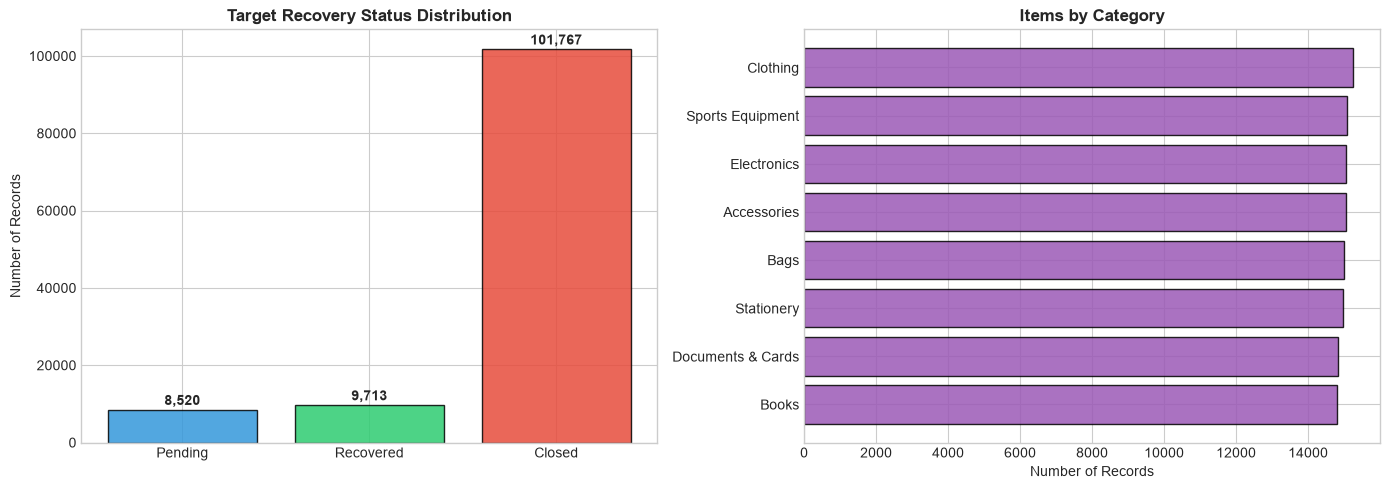

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Target Class Breakdown
status_order = ['Pending', 'Recovered', 'Closed']
counts = df['recovery_status'].value_counts().reindex(status_order)
colors = ['#3498db', '#2ecc71', '#e74c3c']

axes[0].bar(counts.index, counts.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title('Target Recovery Status Distribution', fontweight='bold')
axes[0].set_ylabel('Number of Records')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1200, f'{v:,}', ha='center', fontweight='bold')

# Plot 2: Item Categories
cat_counts = df['category'].value_counts()
axes[1].barh(cat_counts.index, cat_counts.values, color='#9b59b6', edgecolor='black', alpha=0.85)
axes[1].set_title('Items by Category', fontweight='bold')
axes[1].set_xlabel('Number of Records')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


## 8. Train/Test Split & Feature Preparation
We inspect feature columns and prepare an 80/20 stratified split for subsequent machine learning model training.


In [ ]:
feature_cols = [
    'item_type', 'category', 'color', 'brand', 'location',
    'item_age_days', 'description_length', 'has_brand', 
    'report_month', 'report_day_of_week', 'is_weekend'
]
target_col = 'recovery_status'

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'Training Set: {X_train.shape[0]:,} samples')
print(f'Testing Set:  {X_test.shape[0]:,} samples')


Training Set: 96,000 samples
Testing Set:  24,000 samples


## 9. Save Clean Processed Dataset
We export the final cleaned dataset with all engineered features.


In [ ]:
OUTPUT_CLEAN_PATH = os.path.join('..', 'data', 'smart_campus_processed_120k.csv')
if not os.path.exists(os.path.dirname(OUTPUT_CLEAN_PATH)):
    OUTPUT_CLEAN_PATH = r'C:\Users\GOPI CHAND\OneDrive\Documents\AI PROJECT\smart-campus-lost-found\data\smart_campus_processed_120k.csv'

df.to_csv(OUTPUT_CLEAN_PATH, index=False)
print(f'[OK] Clean dataset successfully saved to: {OUTPUT_CLEAN_PATH}')
print(f'Final Rows: {len(df):,}, Final Columns: {df.shape[1]}')


[OK] Clean dataset successfully saved to: C:\Users\GOPI CHAND\OneDrive\Documents\AI PROJECT\smart-campus-lost-found\data\smart_campus_processed_120k.csv
Final Rows: 120,000, Final Columns: 17
